# 🌸 PyTorch ile Çoklu Sınıflandırma (Multi-Class Classification) & Model Kaydetme / Yükleme (.pth)

Bu notebook'ta **PyTorch** kullanarak 3 veya daha fazla sınıftan oluşan **Çoklu Sınıflandırma (Multi-Class Classification)** problemlerini baştan sona inceliyoruz.

### 📌 Öğrenilecek Ana Konular:
1. **Veri Seti Hazırlığı & Label Encoding:** 4 özellikli Iris çiçek veri setini okuma, `LabelEncoder` ile metin etiketlerini (setosa, versicolor, virginica) sayısal sınıflara (0, 1, 2) dönüştürme ve dengeli ayrım için `stratify=y` kullanımı.
2. **Kritik Tenzör Kuralı:** Çoklu sınıflandırmada girdiler `float32`, hedef etiketler ise `nn.CrossEntropyLoss` gereği **`torch.long` (int64)** ve 1 Boyutlu `(N,)` olmalıdır.
3. **Model Mimarisi (`nn.Sequential`):** `Linear(4, 16) -> ReLU -> Linear(16, 16) -> ReLU -> Linear(16, 3)` mimarisi.
4. **Çoklu Sınıflandırma Tahmin Zinciri:**
   $$\text{Raw Logits } (N, 3) \xrightarrow{\text{torch.softmax(dim=1)}} \text{Olasılık Dağılımı } [0.0 - 1.0] \xrightarrow{\text{torch.argmax(dim=1)}} \text{En Yüksek Olasılıklı Sınıf } \{0, 1, 2\}$$
5. **Kayıp Fonksiyonu & Metrikler:** `nn.CrossEntropyLoss()`, `torchmetrics` ile `MulticlassAccuracy` ve `MulticlassConfusionMatrix` (Karmaşıklık Matrisi).
6. **Model Kaydetme ve Yükleme (Saving & Loading .pth):** `model.state_dict()`, `torch.save()`, `torch.load()` ve `load_state_dict()` ile modeli diske kaydedip yeniden ayağa kaldırma.
7. **Production Inference:** Eğitilmiş model ile sıfırdan yeni bir çiçek ölçümü (`new_sample`) üzerinde tahmin yürütme.

## 1. Gerekli Kütüphanelerin Yüklenmesi

In [1]:
import torch
from torch import nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from pathlib import Path

# Cihaz kontrolü
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(f"PyTorch Versiyonu: {torch.__version__} | Aktif Cihaz: {device}")

PyTorch Versiyonu: 2.14.0 | Aktif Cihaz: mps


## 2. Iris Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)

Iris veri seti 3 farklı çiçek türünün (`Setosa`, `Versicolor`, `Virginica`) 4 fiziksel ölçümünü içerir:
- **`SepalLengthCm`**: Çanak yaprak uzunluğu
- **`SepalWidthCm`**: Çanak yaprak genişliği
- **`PetalLengthCm`**: Taç yaprak uzunluğu
- **`PetalWidthCm`**: Taç yaprak genişliği
- **`Species`**: Çiçek türü (Hedef Değişken - 3 Sınıf)

In [2]:
df = pd.read_csv("09-iris.csv")
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB


In [4]:
# Sınıf dağılımını kontrol et (Her sınıftan 50 adet - Tam dengeli veri)
print("Sınıf Sayıları:\\n", df["Species"].value_counts())

Sınıf Sayıları:\n Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


### 📊 Veri Dağılımı (Taç Yaprak Boyutlarına Göre)

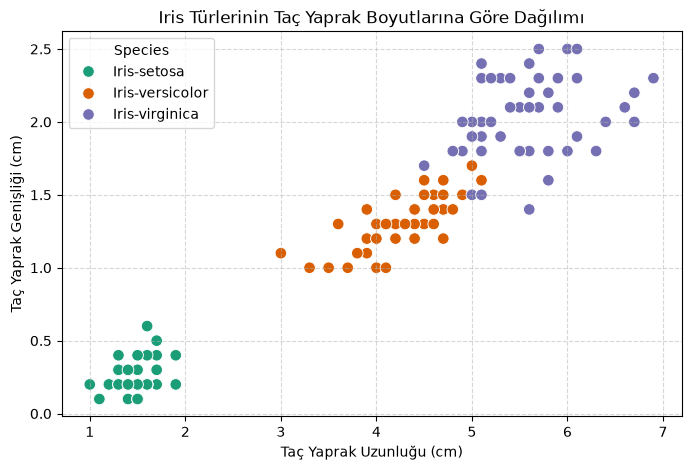

In [5]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df["PetalLengthCm"], y=df["PetalWidthCm"], hue=df["Species"], palette="Dark2", s=70)
plt.title("Iris Türlerinin Taç Yaprak Boyutlarına Göre Dağılımı")
plt.xlabel("Taç Yaprak Uzunluğu (cm)")
plt.ylabel("Taç Yaprak Genişliği (cm)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [6]:
# Model için gereksiz olan 'Id' sütununu kaldırıyoruz
df = df.drop("Id", axis=1)
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## 3. Özellik (X) - Hedef (y) Ayrımı & Label Encoding (Etiket Kodlama)

Metin halindeki tür isimlerini (`Iris-setosa`, `Iris-versicolor`, `Iris-virginica`) modelin anlayacağı sayısal tamsayılara (`0, 1, 2`) dönüştürüyoruz.

In [7]:
# Özellik matrisi (4 sütun)
X = df[["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]].values
# Hedef etiketler (Metin)
y = df["Species"].values

print(f"X shape: {X.shape} | y shape: {y.shape}")

X shape: (150, 4) | y shape: (150,)


In [8]:
# LabelEncoder ile metin etiketlerini 0, 1, 2 sayılarına çeviriyoruz
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Sınıf eşleşmelerini yazdır
for idx, class_name in enumerate(le.classes_):
    print(f"Sınıf {idx} -> {class_name}")

Sınıf 0 -> Iris-setosa
Sınıf 1 -> Iris-versicolor
Sınıf 2 -> Iris-virginica


### Train / Test Ayrımı (`stratify=y` Önemi)
> [!IMPORTANT]
> Çoklu sınıflandırmada `stratify=y` parametresi hayati öneme sahiptir!
> Veriyi bölerken hem eğitim kümesine hem de test kümesine **her bir sınıftan eşit oranda (oranları koruyarak)** örnek dağıtılmasını garanti eder.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Train Büyüklüğü: {len(X_train)} | Test Büyüklüğü: {len(X_test)}")
print("Test Kümesindeki Sınıf Dağılımı (Her sınıftan eşit 10 adet):\\n", pd.Series(y_test).value_counts())

Train Büyüklüğü: 120 | Test Büyüklüğü: 30
Test Kümesindeki Sınıf Dağılımı (Her sınıftan eşit 10 adet):\n 0    10
2    10
1    10
Name: count, dtype: int64


## 4. PyTorch Tenzörlerine Dönüştürme (Kritik Veri Tipi Kuralı)

> [!WARNING]
> **Çoklu Sınıflandırmada Veri Tipi ve Boyut Kuralı:**
> 1. **Girdiler (`X`):** Katman ağırlıklarıyla çarpılacağı için `dtype=torch.float32` olmalıdır (`ndim=2`).
> 2. **Etiketler (`y`):** `nn.CrossEntropyLoss()` fonksiyonu girdi olarak sınıf indekslerini (0, 1, 2) bekler. Bu nedenle etiketler **`dtype=torch.long` (int64)** olmalı ve **1 Boyutlu `(N,)`** kalmalıdır! (`unsqueeze(1)` YAPILMAZ!).

In [10]:
# Girdileri float32, Etiketleri long (int64) yapıyoruz
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test  = torch.tensor(X_test,  dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test  = torch.tensor(y_test,  dtype=torch.long)

print("Tenzör Boyutları ve Tipleri:")
print(f"X_train: {X_train.shape} (dtype: {X_train.dtype})")
print(f"y_train: {y_train.shape} (dtype: {y_train.dtype})")

Tenzör Boyutları ve Tipleri:
X_train: torch.Size([120, 4]) (dtype: torch.float32)
y_train: torch.Size([120]) (dtype: torch.int64)


## 5. Çoklu Sınıflandırma Model Mimarisi (`nn.Sequential`)

Modelimiz 4 girdi özelliğini alır, 2 gizli katmanda 16 nöron ve ReLU ile işler, en sonda **3 sınıf için 3 adet ham lojit** üretir.

In [11]:
class IrisClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        # Katmanları düzenli bir blok halinde tanımlamak için nn.Sequential kullanıyoruz
        self.linear_layer_stack = nn.Sequential(
            nn.Linear(in_features=4, out_features=16), # 4 özellik -> 16 nöron
            nn.ReLU(),                                 # Doğrusalsızlık aktivasyonu
            nn.Linear(in_features=16, out_features=16),# 16 nöron -> 16 nöron
            nn.ReLU(),                                 # Doğrusalsızlık aktivasyonu
            nn.Linear(in_features=16, out_features=3)  # 16 nöron -> 3 Sınıf (Logits)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer_stack(x)

# Modeli oluştur
model = IrisClassifier()
print(model)

IrisClassifier(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)


## 6. Çoklu Sınıflandırmada Tahmin Zinciri: Logits $\rightarrow$ Softmax $\rightarrow$ Argmax

Çoklu sınıflandırmada modelden çıkan çıktıyı adım adım inceliyoruz:

```
[ Model ] ──> Raw Logits (N, 3) ──> torch.softmax(dim=1) ──> Olasılıklar [0-1] ──> torch.argmax(dim=1) ──> Tahmin Sınıfı {0, 1, 2}
```

- **`torch.softmax(logits, dim=1)`**: Her satırdaki 3 lojit değerini toplamı tam $1.0$ (%100) olan olasılık dağılımına dönüştürür.
- **`torch.argmax(dim=1)`**: Olasılığı en yüksek olan sütunun indeksini (0, 1 veya 2) seçer.

In [12]:
# Eğitilmemiş modelden ilk 5 test örneği için lojit çıktısı alıyoruz
y_logits = model(X_test)
print("1. Ham Lojitler (İlk 5 örnek):\n", y_logits[:5])

1. Ham Lojitler (İlk 5 örnek):
 tensor([[0.0290, 0.3414, 0.3707],
        [0.1951, 0.1490, 0.1367],
        [0.1643, 0.1494, 0.1452],
        [0.1643, 0.1416, 0.1427],
        [0.0133, 0.3719, 0.3985]], grad_fn=<SliceBackward0>)


In [13]:
# Lojitleri Softmax ile olasılık dağılımına çeviriyoruz
y_pred_probs = torch.softmax(y_logits, dim=1)
print("2. Softmax Olasılıkları (İlk 5 örnek):\n", y_pred_probs[:5])
print("\nİlk örneğin olasılıklar toplamı (Her zaman 1.0 olmalı):", torch.sum(y_pred_probs[0]).item())

2. Softmax Olasılıkları (İlk 5 örnek):
 tensor([[0.2650, 0.3621, 0.3729],
        [0.3450, 0.3295, 0.3255],
        [0.3371, 0.3321, 0.3308],
        [0.3383, 0.3307, 0.3310],
        [0.2563, 0.3669, 0.3768]], grad_fn=<SliceBackward0>)

İlk örneğin olasılıklar toplamı (Her zaman 1.0 olmalı): 1.0000001192092896


In [14]:
# En yüksek olasılığa sahip sınıfı argmax ile seçiyoruz
y_preds = torch.argmax(y_pred_probs, dim=1)
print("3. Tahmin Edilen Sınıf İndeksleri (İlk 5 örnek):\n", y_preds[:5])
print("Gerçek Test Sınıfları (İlk 5 örnek):\n", y_test[:5])

3. Tahmin Edilen Sınıf İndeksleri (İlk 5 örnek):
 tensor([2, 0, 0, 0, 2])
Gerçek Test Sınıfları (İlk 5 örnek):
 tensor([0, 2, 1, 1, 0])


## 7. Model Eğitimi (Training Loop - 200 Epoch)

- **Kayıp Fonksiyonu:** `nn.CrossEntropyLoss()` $\rightarrow$ Ham lojitleri doğrudan alır, arka planda Softmax + Negative Log Likelihood işlemlerini birleştirir.
- **Optimizer:** `torch.optim.Adam(lr=0.01)`

In [15]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.01)

def calculate_accuracy(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return (correct / len(y_pred)) * 100

In [16]:
torch.manual_seed(42)
epochs = 200

# Metrikleri kaydetmek için listeler
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(epochs):
    # --- 1. EĞİTİM MODU ---
    model.train()
    logits = model(X_train)
    loss = loss_fn(logits, y_train)
    pred = torch.argmax(logits, dim=1)
    acc = calculate_accuracy(y_train, pred)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # --- 2. DEĞERLENDİRME (TEST) MODU ---
    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test)
        test_loss = loss_fn(test_logits, y_test)
        test_pred = torch.argmax(test_logits, dim=1)
        test_acc = calculate_accuracy(y_test, test_pred)

    train_losses.append(loss.item())
    test_losses.append(test_loss.item())
    train_accuracies.append(acc)
    test_accuracies.append(test_acc)

    if epoch % 20 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:3d} | Train Loss: {loss:.4f} | Train Acc: %{acc:.2f} | Test Loss: {test_loss:.4f} | Test Acc: %{test_acc:.2f}")

Epoch   0 | Train Loss: 1.1975 | Train Acc: %0.00 | Test Loss: 1.1437 | Test Acc: %3.33
Epoch  20 | Train Loss: 0.5846 | Train Acc: %69.17 | Test Loss: 0.5513 | Test Acc: %73.33
Epoch  40 | Train Loss: 0.2307 | Train Acc: %97.50 | Test Loss: 0.2243 | Test Acc: %96.67
Epoch  60 | Train Loss: 0.0785 | Train Acc: %97.50 | Test Loss: 0.0823 | Test Acc: %96.67
Epoch  80 | Train Loss: 0.0597 | Train Acc: %97.50 | Test Loss: 0.0562 | Test Acc: %100.00
Epoch 100 | Train Loss: 0.0548 | Train Acc: %98.33 | Test Loss: 0.0478 | Test Acc: %100.00
Epoch 120 | Train Loss: 0.0523 | Train Acc: %98.33 | Test Loss: 0.0450 | Test Acc: %100.00
Epoch 140 | Train Loss: 0.0503 | Train Acc: %98.33 | Test Loss: 0.0441 | Test Acc: %100.00
Epoch 160 | Train Loss: 0.0487 | Train Acc: %98.33 | Test Loss: 0.0445 | Test Acc: %100.00
Epoch 180 | Train Loss: 0.0475 | Train Acc: %98.33 | Test Loss: 0.0443 | Test Acc: %100.00
Epoch 199 | Train Loss: 0.0463 | Train Acc: %98.33 | Test Loss: 0.0462 | Test Acc: %100.00


## 8. Eğitim Öğrenme Eğrileri (Loss ve Accuracy Grafikleri)

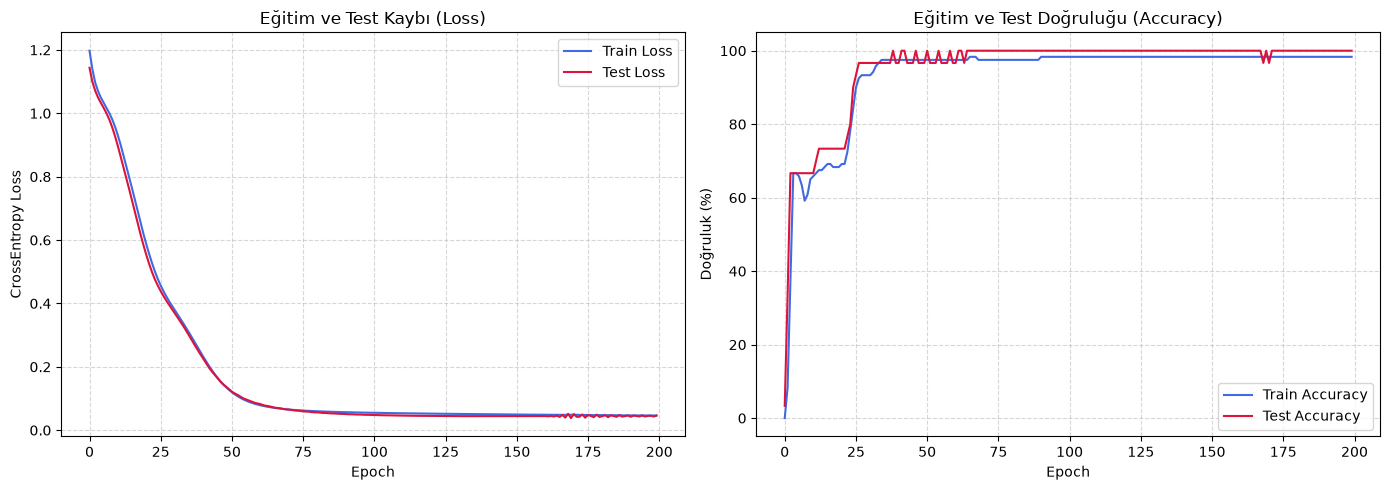

In [17]:
plt.figure(figsize=(14, 5))

# Kayıp (Loss) Grafiği
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss", color="royalblue")
plt.plot(test_losses, label="Test Loss", color="crimson")
plt.title("Eğitim ve Test Kaybı (Loss)")
plt.xlabel("Epoch")
plt.ylabel("CrossEntropy Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

# Doğruluk (Accuracy) Grafiği
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Train Accuracy", color="royalblue")
plt.plot(test_accuracies, label="Test Accuracy", color="crimson")
plt.title("Eğitim ve Test Doğruluğu (Accuracy)")
plt.xlabel("Epoch")
plt.ylabel("Doğruluk (%)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 9. `torchmetrics` ile Değerlendirme & Confusion Matrix (Karmaşıklık Matrisi)

In [18]:
from torchmetrics.classification import MulticlassAccuracy, MulticlassConfusionMatrix
from torchmetrics.utilities.plot import plot_confusion_matrix

# Torchmetrics Accuracy hesaplama
metric_acc = MulticlassAccuracy(num_classes=3)
final_test_acc = metric_acc(test_pred, y_test).item() * 100
print(f"TorchMetrics Test Doğruluğu: %{final_test_acc:.2f}")

TorchMetrics Test Doğruluğu: %100.00


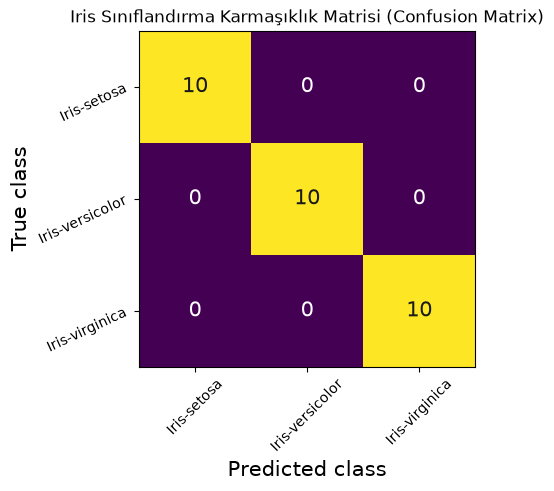

In [19]:
# Confusion Matrix (Karmaşıklık Matrisi) Çizimi
cm = MulticlassConfusionMatrix(num_classes=3)
matrix = cm(test_pred, y_test)

fig, ax = plot_confusion_matrix(matrix, labels=list(le.classes_))
plt.title("Iris Sınıflandırma Karmaşıklık Matrisi (Confusion Matrix)")
plt.show()

## 10. PyTorch Modelini Kaydetme, Yükleme (.pth) & Production Tahmini

Modeli eğitip başarıya ulaştırdıktan sonra bellekte bırakmayız; web servislerinde veya mobil uygulamalarda kullanmak üzere **diske kaydederiz (`.pth`)**.

### 💡 Neden `state_dict()` Kaydedilir?
PyTorch'ta tüm modeli doğrudan kaydetmek yerine **`model.state_dict()`** (öğrenilen ağırlık ve bias matrisleri sözlüğü) kaydedilir. 
Bu sektör standardıdır; dosya boyutu çok küçüktür (birkaç kilobayt) ve versiyon uyumsuzluğu problemlerini önler.

In [20]:
# 1. Kayıt klasörünü oluştur
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "iris_classification_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 2. Modelin ağırlıklarını diske kaydet
print(f"Model kaydediliyor: {MODEL_SAVE_PATH}")
torch.save(obj=model.state_dict(), f=MODEL_SAVE_PATH)
print("Model başarıyla kaydedildi! ✅")

Model kaydediliyor: models/iris_classification_model.pth
Model başarıyla kaydedildi! ✅


### 📥 Kaydedilen Modeli Diskten Yükleme (Loading `.pth`)
Modeli yüklerken iki adım izlenir:
1. Aynı mimaride boş bir model nesnesi oluşturulur (`loaded_model = IrisClassifier()`).
2. Diskteki ağırlıklar `torch.load()` ile okunup `load_state_dict()` ile modele yüklenir.

In [21]:
# 1. Boş model mimarisini oluştur
loaded_model = IrisClassifier()

# 2. Diskteki ağırlıkları yükle
loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

# 3. Modeli değerlendirme (test) moduna al
loaded_model.eval()
print("Model diskten başarıyla yüklendi ve hazır! ✅")

Model diskten başarıyla yüklendi ve hazır! ✅


### 🔮 Canlı Test (Yeni Bir Çiçek Örneği ile Tahmin)

In [22]:
# Yeni ölçüm: [SepalLength, SepalWidth, PetalLength, PetalWidth]
new_sample = np.array([[5.1, 3.5, 1.4, 0.2]]) # Örnek Setosa ölçüleri
new_sample_tensor = torch.tensor(new_sample, dtype=torch.float32)

# Yüklenen model ile tahmin
with torch.inference_mode():
    sample_logits = loaded_model(new_sample_tensor)
    sample_probs = torch.softmax(sample_logits, dim=1)
    sample_pred_idx = torch.argmax(sample_probs, dim=1).item()

predicted_species = le.inverse_transform([sample_pred_idx])[0]
confidence = sample_probs[0][sample_pred_idx].item() * 100

print(f"Girdi Değerleri: {new_sample[0]}")
print(f"Tahmin Edilen Sınıf İndeksi : {sample_pred_idx}")
print(f"Tahmin Edilen Çiçek Türü    : {predicted_species}")
print(f"Modelin Güven Oranı (Confidence): %{confidence:.2f}")

Girdi Değerleri: [5.1 3.5 1.4 0.2]
Tahmin Edilen Sınıf İndeksi : 0
Tahmin Edilen Çiçek Türü    : Iris-setosa
Modelin Güven Oranı (Confidence): %99.99


## 📝 Modül Özeti & Kritik Bilgiler

| Kavram / Görev | İkili Sınıflandırma (Binary) | Çoklu Sınıflandırma (Multi-Class) |
| :--- | :--- | :--- |
| **Örnek Problem** | Deprem Var / Yok (0 vs 1) | Çiçek Türü: Setosa, Versicolor, Virginica (0, 1, 2) |
| **Çıkış Katmanı Nöron Sayısı** | `out_features = 1` | `out_features = Sınıf_Sayısı (3)` |
| **Hedef Etiket (`y`) Formatı** | `dtype=torch.float32`, `shape=(N, 1)` | `dtype=torch.long`, `shape=(N,)` |
| **Olasılık Fonksiyonu** | `torch.sigmoid(logits)` | `torch.softmax(logits, dim=1)` |
| **Son Karar Fonksiyonu** | `torch.round(probs)` (0.5 Eşiği) | `torch.argmax(probs, dim=1)` |
| **Kayıp Fonksiyonu** | `nn.BCEWithLogitsLoss()` | `nn.CrossEntropyLoss()` |
| **Model Kaydetme** | `torch.save(model.state_dict(), path)` | `torch.save(model.state_dict(), path)` |

---
*Proje Rehberi: Atıl Samancıoğlu Derin Öğrenme Eğitimi Modül 09*